<a href="https://colab.research.google.com/github/Temmy-bit/computer-vision-lab/blob/main/Binary_Emotion_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab.patches import cv2_imshow
import zipfile
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, Flatten, BatchNormalization

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
path = '/content/drive/MyDrive/Computer Vision Masterclass/Datasets/fer2013_2_classes.zip'

In [ ]:
zip_object = zipfile.ZipFile(file=path, mode='r')
zip_object.extractall('./')
zip_object.close()

In [ ]:
training_generator = ImageDataGenerator(rescale=1./255,
                                        rotation_range=7,
                                        horizontal_flip=True,
                                        zoom_range=0.2)

train_dataset = training_generator.flow_from_directory('/content/fer2013_2_classes/train',
                                                    target_size=(48,48),
                                                       batch_size = 16,
                                                       class_mode='categorical',
                                                       shuffle=True)

Found 11210 images belonging to 2 classes.


In [ ]:
train_dataset.classes

array([0, 0, 0, ..., 1, 1, 1], dtype=int32)

In [ ]:
train_dataset.class_indices

{'Angry': 0, 'Happy': 1}

In [ ]:
np.unique(train_dataset.classes,return_counts=True)

(array([0, 1], dtype=int32), array([3995, 7215]))

/tmp/ipython-input-633639664.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=train_dataset.classes,palette="pastel");


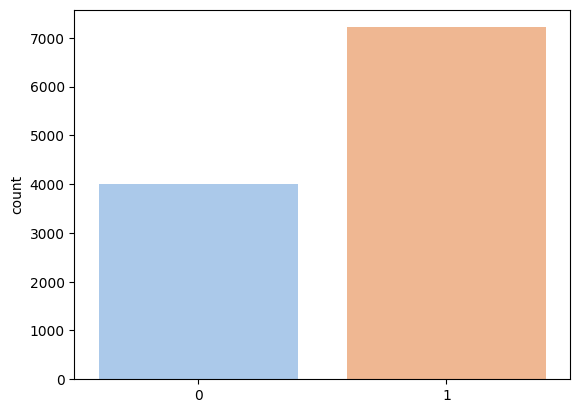

In [ ]:
sns.countplot(x=train_dataset.classes,palette="pastel");

In [ ]:
test_generator = ImageDataGenerator(rescale=1./255)
test_dataset = test_generator.flow_from_directory('/content/fer2013_2_classes/validation',
                                                  target_size = (48,48),
                                                  batch_size = 1,
                                                  class_mode = 'categorical',
                                                  shuffle=False)

Found 1370 images belonging to 2 classes.


In [ ]:
num_detector = 32
num_classes = 2
width, height = 48,48
epochs = 5

network = Sequential()
network.add(Conv2D(num_detector, (3,3), activation='relu', input_shape=(width,height,3),padding='same'))
network.add(BatchNormalization())
# network.add(MaxPooling2D(pool_size=(2,2)))
network.add(Conv2D(num_detector, (3,3), activation='relu',padding='same'))
network.add(BatchNormalization())
network.add(MaxPooling2D(pool_size=(2,2)))
network.add(Dropout(0.2))

network.add(Conv2D(2*num_detector, (3,3), activation='relu',padding='same'))
network.add(BatchNormalization())
# network.add(MaxPooling2D(pool_size=(2,2)))
network.add(Conv2D(2*num_detector, (3,3), activation='relu',padding='same'))
network.add(BatchNormalization())
network.add(MaxPooling2D(pool_size=(2,2)))
network.add(Dropout(0.2))

network.add(Conv2D(2*2*num_detector, (3,3), activation='relu',padding='same'))
network.add(BatchNormalization())
# network.add(MaxPooling2D(pool_size=(2,2)))
network.add(Conv2D(2*2*num_detector, (3,3), activation='relu',padding='same'))
network.add(BatchNormalization())
network.add(MaxPooling2D(pool_size=(2,2)))
network.add(Dropout(0.2))


network.add(Conv2D(2*2*2*num_detector, (3,3), activation='relu',padding='same'))
network.add(BatchNormalization())
# network.add(MaxPooling2D(pool_size=(2,2)))
network.add(Conv2D(2*2*2*num_detector, (3,3), activation='relu',padding='same'))
network.add(BatchNormalization())
network.add(MaxPooling2D(pool_size=(2,2)))
network.add(Dropout(0.2))

network.add(Flatten())

network.add(Dense(2*num_detector,activation='relu'))
network.add(BatchNormalization())
network.add(Dropout(0.2))

network.add(Dense(2*num_detector,activation='relu'))
network.add(BatchNormalization())
network.add(Dropout(0.2))

network.add(Dense(num_classes,activation='softmax'))

network.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [ ]:
network.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_35          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_36          │ (None, 6, 6, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 6, 6, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,328,418 (5.07 MB)

 Trainable params: 1,326,242 (5.06 MB)

 Non-trainable params: 2,176 (8.50 KB)

In [ ]:
network.fit(train_dataset,epochs=epochs,validation_data=test_dataset)

Epoch 1/5
701/701 ━━━━━━━━━━━━━━━━━━━━ 341s 473ms/step - accuracy: 0.5764 - loss: 0.8235 - val_accuracy: 0.6942 - val_loss: 0.5934
Epoch 2/5
701/701 ━━━━━━━━━━━━━━━━━━━━ 325s 463ms/step - accuracy: 0.7014 - loss: 0.5818 - val_accuracy: 0.8080 - val_loss: 0.4322
Epoch 3/5
701/701 ━━━━━━━━━━━━━━━━━━━━ 324s 462ms/step - accuracy: 0.7696 - loss: 0.4785 - val_accuracy: 0.7810 - val_loss: 0.4503
Epoch 4/5
701/701 ━━━━━━━━━━━━━━━━━━━━ 319s 455ms/step - accuracy: 0.8095 - loss: 0.4147 - val_accuracy: 0.8496 - val_loss: 0.3463
Epoch 5/5
701/701 ━━━━━━━━━━━━━━━━━━━━ 328s 468ms/step - accuracy: 0.8482 - loss: 0.3496 - val_accuracy: 0.8686 - val_loss: 0.3086


In [ ]:
from keras.src.saving.saving_api import save_model
model_json = network.to_json()
with open("model.json", "w") as json_file:
    json_file.write(model_json)

from keras.models import save_model
network_saved = save_model(network, "model.hdf5")
# network.save_model("model.hdf5")
print("Saved model to disk")

Saved model to disk


In [ ]:
with open('model.json', 'r') as json_file:
    json_savedModel= json_file.read()
json_savedModel

'{"module": "keras", "class_name": "Sequential", "config": {"name": "sequential_3", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "layers": [{"module": "keras.layers", "class_name": "InputLayer", "config": {"batch_shape": [null, 48, 48, 3], "dtype": "float32", "sparse": false, "ragged": false, "name": "input_layer_3"}, "registered_name": null}, {"module": "keras.layers", "class_name": "Conv2D", "config": {"name": "conv2d_24", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "filters": 32, "kernel_size": [3, 3], "strides": [1, 1], "padding": "same", "data_format": "channels_last", "dilation_rate": [1, 1], "groups": 1, "activation": "relu", "use_bias": true, "kernel_initializer": {"module": "keras.initializers", "class_name": "GlorotUniform", "config": {"seed": null}, "registered_name": null}, "bias_initializer": {"mo

In [ ]:
network_loaded = tf.keras.models.model_from_json(json_savedModel)
network_loaded.load_weights('/content/model.hdf5')
network_loaded.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_35          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_36          │ (None, 6, 6, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 6, 6, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 3,980,904 (15.19 MB)

 Trainable params: 1,326,242 (5.06 MB)

 Non-trainable params: 2,176 (8.50 KB)

 Optimizer params: 2,652,486 (10.12 MB)

In [ ]:
network_loaded.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [ ]:
network_loaded.evaluate(test_dataset)

1370/1370 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.8271 - loss: 0.3530


[0.3085501194000244, 0.8686131238937378]

In [ ]:
predictions = network_loaded.predict(test_dataset)
predictions

1370/1370 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step


array([[0.9916511 , 0.00834883],
       [0.8524398 , 0.14756018],
       [0.56103224, 0.43896782],
       ...,
       [0.05174357, 0.9482564 ],
       [0.03713855, 0.9628615 ],
       [0.06882723, 0.9311728 ]], dtype=float32)

In [ ]:
predictions = np.argmax(predictions,axis=1)
predictions

array([0, 0, 0, ..., 1, 1, 1])

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true=test_dataset.classes,y_pred=predictions)
cm

array([[391, 100],
       [ 80, 799]])

<Axes: >

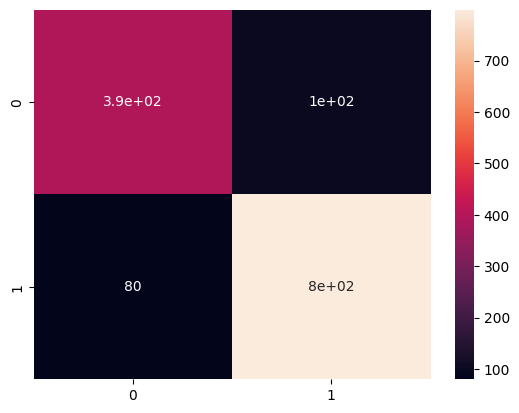

In [ ]:
sns.heatmap(cm,annot=True)

In [ ]:
from sklearn.metrics import classification_report,accuracy_score
print(classification_report(y_true=test_dataset.classes,y_pred=predictions))

              precision    recall  f1-score   support

           0       0.83      0.80      0.81       491
           1       0.89      0.91      0.90       879

    accuracy                           0.87      1370
   macro avg       0.86      0.85      0.86      1370
weighted avg       0.87      0.87      0.87      1370



In [ ]:
accuracy_score(y_true=test_dataset.classes,y_pred=predictions)

0.8686131386861314

array([[[105, 105, 105],
        [110, 110, 110],
        [114, 114, 114],
        ...,
        [ 31,  31,  31],
        [ 32,  32,  32],
        [ 31,  31,  31]],

       [[106, 106, 106],
        [112, 112, 112],
        [117, 117, 117],
        ...,
        [ 32,  32,  32],
        [ 33,  33,  33],
        [ 32,  32,  32]],

       [[103, 103, 103],
        [110, 110, 110],
        [117, 117, 117],
        ...,
        [ 33,  33,  33],
        [ 34,  34,  34],
        [ 34,  34,  34]],

       ...,

       [[ 42,  42,  42],
        [ 48,  48,  48],
        [ 53,  53,  53],
        ...,
        [109, 109, 109],
        [ 94,  94,  94],
        [ 97,  97,  97]],

       [[ 40,  40,  40],
        [ 44,  44,  44],
        [ 49,  49,  49],
        ...,
        [117, 117, 117],
        [ 99,  99,  99],
        [ 94,  94,  94]],

       [[ 39,  39,  39],
        [ 41,  41,  41],
        [ 45,  45,  45],
        ...,
        [120, 120, 120],
        [107, 107, 107],
        [ 96,  96,  96]]], dtype=uint8)
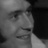

In [ ]:
image = cv2.imread('/content/fer2013_2_classes/validation/Happy/103.jpg')
image

In [ ]:
face_detector = cv2.CascadeClassifier('/content/drive/MyDrive/Computer Vision Masterclass/Cascades/haarcascade_frontalface_default.xml')

In [ ]:
original_image = image.copy()
faces = face_detector.detectMultiScale(original_image)

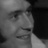

In [ ]:
cv2_imshow(original_image)

In [ ]:
network_loaded.evaluate(test_dataset)

1370/1370 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.8271 - loss: 0.3530


[0.3085501194000244, 0.8686131238937378]

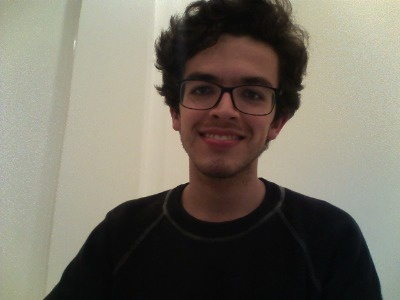

In [ ]:
img = cv2.imread('/content/drive/MyDrive/Computer Vision Masterclass/Images/gabriel.png')
cv2_imshow(img)

In [ ]:
original_img = img.copy()
faces = face_detector.detectMultiScale(original_img)

In [ ]:
faces

array([[162,  40, 128, 128]], dtype=int32)

# Task
Draw rectangles on the detected faces in `img` using the `faces` variable and then display the image with the drawn rectangles.

## Draw Rectangles on Faces

### Subtask:
Iterate through the detected faces in the 'faces' variable and draw rectangles on the 'original_img' using the coordinates provided by the face detector.


**Reasoning**:
To draw rectangles on the detected faces, I need to iterate through the `faces` array and use `cv2.rectangle()` with the provided coordinates, color, and thickness.



In [ ]:
for (x, y, w, h) in faces:
    cv2.rectangle(original_img, (x, y), (x + w, y + h), (0, 255, 0), 2)


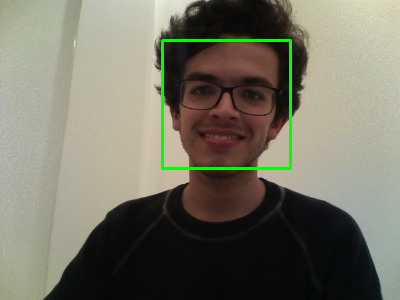

In [ ]:
cv2_imshow(original_img)

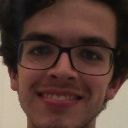

In [ ]:
roi = img[40:40 + 128, 162:162 + 128]
cv2_imshow(roi)

In [ ]:
roi.shape

(128, 128, 3)

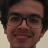

In [ ]:
roi = cv2.resize(roi,(48,48))
cv2_imshow(roi)

In [ ]:
roi = roi/255

In [ ]:
roi.shape

(48, 48, 3)

In [ ]:
roi = np.expand_dims(roi,axis=0)
roi.shape

(1, 48, 48, 3)

In [ ]:
probs = network_loaded.predict(roi)
probs

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 382ms/step


array([[0.18689108, 0.8131089 ]], dtype=float32)

In [ ]:
result = np.argmax(probs)
result

np.int64(1)

In [ ]:
test_dataset.class_indices

{'Angry': 0, 'Happy': 1}

Classifying Multiple Images

In [ ]:
images = cv2.imread('/content/drive/MyDrive/Computer Vision Masterclass/Images/faces_emotions.png')
cv2_imshow(images)

In [ ]:
faces = face_detector.detectMultiScale(images)
faces

In [ ]:
test_dataset.class_indices.keys()

In [ ]:
emotions = ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']

In [ ]:
for (x, y, w, h) in faces:
    cv2.rectangle(images, (x, y), (x + w, y + h), (0, 255, 0), 2)
    roi = images[y:y + h, x:x + w]
    roi = cv2.resize(roi,(48,48))
    # cv2_imshow(roi)
    roi = roi/255
    roi = np.expand_dims(roi,axis=0)
    # print(roi.shape)
    predictions = network_loaded.predict(roi)
    result = np.argmax(predictions)
    # cv2_imshow(roi)
    # print(result)
    cv2.putText(images,emotions[result],(x,y-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
cv2_imshow(images)

In [ ]:
cap = cv2.VideoCapture('/content/drive/MyDrive/Computer Vision Masterclass/Videos/emotion_test01.mp4')
connected, video = cap.read()
print(connected,video.shape)

In [ ]:
save_path = '/content/drive/MyDrive/result.avi'
fourcc = cv2.VideoWriter_fourcc(*'XVID')
fps = 20
out = cv2.VideoWriter(save_path,fourcc,fps,(video.shape[1],video.shape[0]))

In [ ]:
while (cv2.waitKey(1) < 0):
    connected, frame = cap.read()
    if connected == False:
        break
    faces = face_detector.detectMultiScale(frame)
    if len(faces) > 0:
      for (x, y, w, h) in faces:
        frame = cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
        roi = frame[y:y + h, x:x + w]

        roi = cv2.resize(roi,(48,48))
        # cv2_imshow(roi)
        roi = roi/255
        roi = np.expand_dims(roi,axis=0)
        # print(roi.shape)
        predictions = network_loaded.predict(roi)
        # result = np.argmax(predictions)

        if predictions is not None:
          result = np.argmax(predictions)
          cv2.putText(frame,emotions[result],(x,y-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2,cv2.LINE_AA)

    cv2_imshow(frame)
    out.write(frame)

print('End')
out.release()
cv2.destroyAllWindows()